In [1]:
import nltk
import pandas as pd

# Download the movie review dataset
nltk.download("movie_reviews")

# Import the dataset
from nltk.corpus import movie_reviews

print("Dataset downloaded and imported successfully!")
print("Categories:", movie_reviews.categories())

Dataset downloaded and imported successfully!
Categories: ['neg', 'pos']


[nltk_data] Downloading package movie_reviews to
[nltk_data]     C:\Users\yuvan\AppData\Roaming\nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!


In [2]:
# Load all reviews and their categories
documents = [
    (list(movie_reviews.words(fileid)), category)
    for category in movie_reviews.categories()
    for fileid in movie_reviews.fileids(category)
]

# Create a DataFrame
df = pd.DataFrame(documents, columns=["review", "category"])

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (2000, 2)


,review,category
0,"[plot, :, two, teen, couples, go, to, a, churc...",neg
1,"[the, happy, bastard, ', s, quick, movie, revi...",neg
2,"[it, is, movies, like, these, that, make, a, j...",neg
3,"["", quest, for, camelot, "", is, warner, bros, ...",neg
4,"[synopsis, :, a, mentally, unstable, man, unde...",neg


In [3]:
# Convert each review from a list of words into a string
df["review"] = df["review"].apply(lambda words: " ".join(words))

# Inspect the results
print("Data type:", type(df["review"].iloc[0]))
print("Category:", df["category"].iloc[0])
print("\nSample review:")
print(df["review"].iloc[0][:500])

Data type: <class 'str'>
Category: neg

Sample review:
plot : two teen couples go to a church party , drink and then drive . they get into an accident . one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . what ' s the deal ? watch the movie and " sorta " find out . . . critique : a mind - fuck movie for the teen generation that touches on a very cool idea , but presents it in a very bad package . which is what makes this review an even harder one to write , since i generally applaud films which attempt t


In [4]:
from nltk.tokenize import word_tokenize
import spacy

# Load spaCy's English model
nlp_spacy = spacy.load("en_core_web_sm")

# Select one review
sample_text = df["review"].iloc[0][:500]

# NLTK tokenization
nltk_tokens = word_tokenize(sample_text)

# spaCy tokenization
doc = nlp_spacy(sample_text)
spacy_tokens = [token.text for token in doc]

# Compare results
print("Original text:\n", sample_text)
print("\nNLTK tokens:\n", nltk_tokens[:40])
print("\nspaCy tokens:\n", spacy_tokens[:40])

print("\nsamplet text Count:   ",len(sample_text))
print("NLTK token count:     ", len(nltk_tokens))
print("spaCy token count:    ", len(spacy_tokens))

Original text:
 plot : two teen couples go to a church party , drink and then drive . they get into an accident . one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . what ' s the deal ? watch the movie and " sorta " find out . . . critique : a mind - fuck movie for the teen generation that touches on a very cool idea , but presents it in a very bad package . which is what makes this review an even harder one to write , since i generally applaud films which attempt t

NLTK tokens:
 ['plot', ':', 'two', 'teen', 'couples', 'go', 'to', 'a', 'church', 'party', ',', 'drink', 'and', 'then', 'drive', '.', 'they', 'get', 'into', 'an', 'accident', '.', 'one', 'of', 'the', 'guys', 'dies', ',', 'but', 'his', 'girlfriend', 'continues', 'to', 'see', 'him', 'in', 'her', 'life', ',', 'and']

spaCy tokens:
 ['plot', ':', 'two', 'teen', 'couples', 'go', 'to', 'a', 'church', 'party', ',', 'drink', 'and', 'then', 'drive', '.', 'they', 'get', 'into', 'an', 'acc

In [5]:
from tqdm.auto import tqdm

# NLTK tokenization with progress bar
tqdm.pandas(desc="NLTK Tokenization")

df["NLTK_token"] = df["review"].progress_apply(word_tokenize)

# spaCy batch tokenization with progress bar
texts = df["review"].tolist()
batch_size = 64
spacy_tokens = []

for start in tqdm(
    range(0, len(texts), batch_size),
    desc="spaCy Tokenization",
    unit="batch"
):
    batch = texts[start:start + batch_size]

    docs = nlp_spacy.pipe(
        batch,
        batch_size=batch_size
    )

    spacy_tokens.extend(
        [token.text for token in doc]
        for doc in docs
    )

df["Spacy_token"] = spacy_tokens

# Inspect results
df[["review", "NLTK_token", "Spacy_token"]].head()

Y:\Python\AI ML\Month 2\week 7-Deep Learning\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
spaCy Tokenization: 100%|██████████| 32/32 [05:26<00:00, 10.19s/batch]


,review,NLTK_token,Spacy_token
0,"plot : two teen couples go to a church party ,...","[plot, :, two, teen, couples, go, to, a, churc...","[plot, :, two, teen, couples, go, to, a, churc..."
1,the happy bastard ' s quick movie review damn ...,"[the, happy, bastard, ', s, quick, movie, revi...","[the, happy, bastard, ', s, quick, movie, revi..."
2,it is movies like these that make a jaded movi...,"[it, is, movies, like, these, that, make, a, j...","[it, is, movies, like, these, that, make, a, j..."
3,""" quest for camelot "" is warner bros . ' first...","[``, quest, for, camelot, ``, is, warner, bros...","["", quest, for, camelot, "", is, warner, bros, ..."
4,synopsis : a mentally unstable man undergoing ...,"[synopsis, :, a, mentally, unstable, man, unde...","[synopsis, :, a, mentally, unstable, man, unde..."


In [7]:
from nltk.corpus import stopwords
from tqdm.auto import tqdm

# Load English stopwords
stop_words = set(stopwords.words("english"))

# Remove stopwords
def remove_stopwords(tokens):
    return [
        word for word in tokens
        if word.lower() not in stop_words
    ]

# Apply with progress bar
tqdm.pandas(desc="Removing Stopwords")

df["NLTK_no_stopwords"] = df["NLTK_token"].progress_apply(
    remove_stopwords
)

# Verify
print("Dataset shape:", df.shape)
print("\nBefore:")
print(df["NLTK_token"].iloc[0][:40])

print("\nAfter:")
print(df["NLTK_no_stopwords"].iloc[0][:40])

Removing Stopwords: 100%|██████████| 2000/2000 [00:00<00:00, 7338.96it/s]

Dataset shape: (2000, 5)

Before:
['plot', ':', 'two', 'teen', 'couples', 'go', 'to', 'a', 'church', 'party', ',', 'drink', 'and', 'then', 'drive', '.', 'they', 'get', 'into', 'an', 'accident', '.', 'one', 'of', 'the', 'guys', 'dies', ',', 'but', 'his', 'girlfriend', 'continues', 'to', 'see', 'him', 'in', 'her', 'life', ',', 'and']

After:
['plot', ':', 'two', 'teen', 'couples', 'go', 'church', 'party', ',', 'drink', 'drive', '.', 'get', 'accident', '.', 'one', 'guys', 'dies', ',', 'girlfriend', 'continues', 'see', 'life', ',', 'nightmares', '.', "'", 'deal', '?', 'watch', 'movie', '``', 'sorta', '``', 'find', '.', '.', '.', 'critique', ':']


In [8]:
# Lemmatize the reviews

from tqdm.auto import tqdm

# Join filtered tokens back into text
texts = [
    " ".join(tokens)
    for tokens in df["NLTK_no_stopwords"]
]

lemmatized_reviews = []
batch_size = 64

# Process reviews using the full spaCy pipeline
for start in tqdm(
    range(0, len(texts), batch_size),
    desc="spaCy Lemmatization",
    unit="batch"
):
    batch = texts[start:start + batch_size]

    docs = nlp_spacy.pipe(batch, batch_size=batch_size)

    lemmatized_reviews.extend(
        [token.lemma_ for token in doc]
        for doc in docs
    )

# Save the results
df["Spacy_lemmatized"] = lemmatized_reviews

# Compare before and after
print("Before:", df["NLTK_no_stopwords"].iloc[0][:30])
print("After:", df["Spacy_lemmatized"].iloc[0][:30])

spaCy Lemmatization: 100%|██████████| 32/32 [03:14<00:00,  6.07s/batch]

Before: ['plot', ':', 'two', 'teen', 'couples', 'go', 'church', 'party', ',', 'drink', 'drive', '.', 'get', 'accident', '.', 'one', 'guys', 'dies', ',', 'girlfriend', 'continues', 'see', 'life', ',', 'nightmares', '.', "'", 'deal', '?', 'watch']
After: ['plot', ':', 'two', 'teen', 'couple', 'go', 'church', 'party', ',', 'drink', 'drive', '.', 'get', 'accident', '.', 'one', 'guy', 'die', ',', 'girlfriend', 'continue', 'see', 'life', ',', 'nightmare', '.', "'", 'deal', '?', 'watch']


In [9]:
import string
from tqdm.auto import tqdm

# Remove punctuation tokens
def remove_punctuations(tokens):
    return [
        word for word in tokens
        if word not in string.punctuation
    ]

# Apply with progress bar
tqdm.pandas(desc="Removing Punctuation")

df["Spacy_cleaned"] = df["Spacy_lemmatized"].progress_apply(
    remove_punctuations
)

# Inspect the result
print("Before:")
print(df["Spacy_lemmatized"].iloc[0][:40])

print("\nAfter:")
print(df["Spacy_cleaned"].iloc[0][:40])

print("\nDataset shape:", df.shape)

Removing Punctuation: 100%|██████████| 2000/2000 [00:00<00:00, 11797.15it/s]

Before:
['plot', ':', 'two', 'teen', 'couple', 'go', 'church', 'party', ',', 'drink', 'drive', '.', 'get', 'accident', '.', 'one', 'guy', 'die', ',', 'girlfriend', 'continue', 'see', 'life', ',', 'nightmare', '.', "'", 'deal', '?', 'watch', 'movie', '`', '`', 'sorta', '`', '`', 'find', '.', '.', '.']

After:
['plot', 'two', 'teen', 'couple', 'go', 'church', 'party', 'drink', 'drive', 'get', 'accident', 'one', 'guy', 'die', 'girlfriend', 'continue', 'see', 'life', 'nightmare', 'deal', 'watch', 'movie', 'sorta', 'find', 'critique', 'mind', 'fuck', 'movie', 'teen', 'generation', 'touch', 'cool', 'idea', 'present', 'bad', 'package', 'make', 'review', 'even', 'hard']

Dataset shape: (2000, 7)


In [12]:
# Generate Word Clouds

from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Combine all original reviews
original_text = " ".join(df["review"])

# Combine all cleaned reviews
cleaned_text = " ".join(
    " ".join(tokens)
    for tokens in df["Spacy_cleaned"]
)

print("Original text characters:", len(original_text))
print("Cleaned text characters:", len(cleaned_text))

Original text characters: 7810519
Cleaned text characters: 4747178


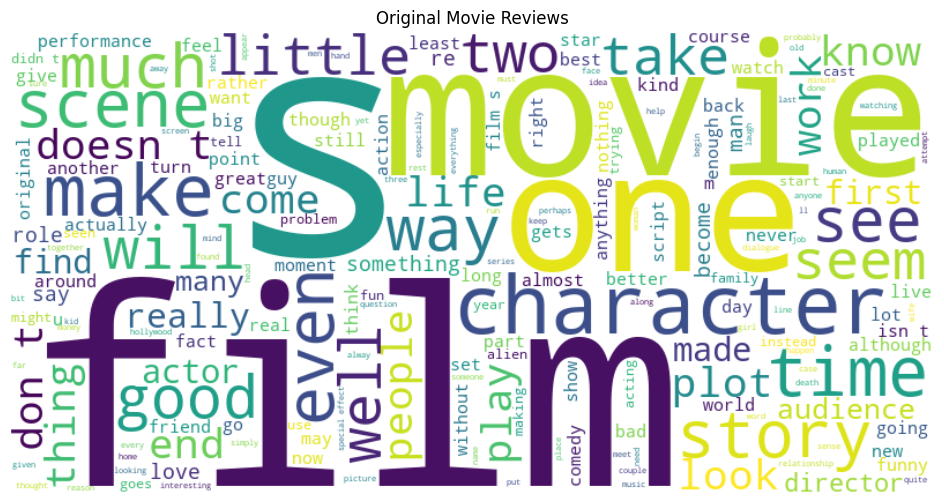

In [13]:
wordcloud_original = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(original_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud_original, interpolation="bilinear")
plt.axis("off")
plt.title("Original Movie Reviews")
plt.show()

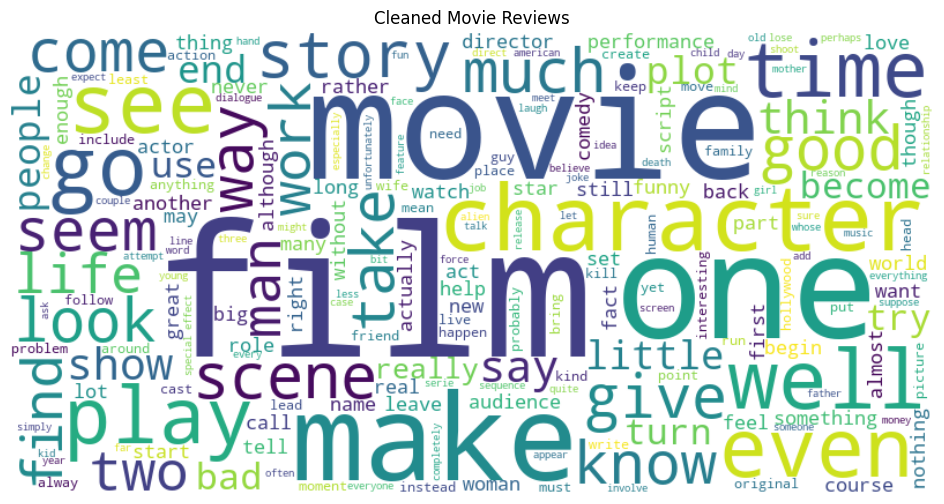

In [14]:
wordcloud_cleaned = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(cleaned_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud_cleaned, interpolation="bilinear")
plt.axis("off")
plt.title("Cleaned Movie Reviews")
plt.show()